# NB3 · The Hands
**From Forms to Agents · Lecture 3 · Tools, APIs and MCP**

The form did nine jobs. This notebook takes over **job 3: looking up codes and facts, and doing the work.**

Kavita's order is the running example: 20,000 silicone gaskets (GSK-SIL-05L) from Deccan Polymers (DP-RJK-0042)
at the contract rate of ₹11.90, ₹2,80,840 gross, above her ₹2,50,000 limit, so Rohit must approve.

What you will do:
1. Look at what a tool is, and at the 38 raw services Bahi offers.
2. Build tools from screens in six steps: inventory, live runs, cascades, variants, screen state, the intent tool.
3. Write `find_supplier` and `create_purchase_order` yourself (exercises 3 and 4).
4. Check the tool contract: types, errors, preview, idempotency key, receipt, validate once, permissions, retry, version.
5. Serve the tools over MCP, next to a "marketplace" email and chat server, and call them through an MCP client.
6. Run the six scenarios with this lecture's agent, and start the same work on your own module (A3).

Everything runs with **no API key** in replay mode: the model replies were recorded in our run (cassette `L3_nb`).
All companies, people, codes and numbers are fictional.

In [1]:
# Setup: install the Bahi sandbox and its recorded model replies. Runs in about a minute on Colab.
# REPLAY mode (the default when you have no key) plays back our recorded model calls, so every cell runs
# without an API key and shows the numbers from our own run. To call a model live, set a key below.
import os, sys, subprocess
COURSE_REPO = "https://github.com/RajatDandekar/agents-for-enterprises"   # course code (Bahi sandbox + reference agent)
try:
    import bahi  # already available (local checkout or Modal)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"bahi-erp[all] @ git+{COURSE_REPO}.git#subdirectory=bahi"], check=True)
    import bahi
# os.environ["GEMINI_API_KEY"] = "..."        # optional: your own key, to run live
# os.environ["OPENROUTER_API_KEY"] = "..."    # optional: GPT, Claude, Llama ... via OpenRouter
os.environ.setdefault("BAHI_LLM_MODE", "auto")  # auto = replay what was recorded, call live only for new requests
print("Bahi", bahi.__version__, "· model mode:", os.environ["BAHI_LLM_MODE"])

Bahi 0.1.0 · model mode: replay


In [2]:
import json, re, copy, importlib, pathlib
import pandas as pd
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

import bahi
from bahi.erp.engine import ERP, SERVICES, PROCS, ServiceTimeout
from bahi.llm import LLM
from bahi.agent import tools as T
from bahi.agent.tools import IntentTools, TOOLS, CORE, ALL, TOOL_CONTRACT, RawServiceTools, GenericServiceTool
from bahi.agent.loop import ToolLoopAgent, SYSTEM, GENERIC_SYSTEM
from bahi.scenarios import SCENARIOS, run_scenario, scorecard

MODEL = "gemini:gemini-3.8-flash"
CASSETTE = "L3_nb"
def show(obj, n=1800):
    """Print JSON the way a tool returns it (cut at n characters)."""
    s = json.dumps(obj, indent=1, ensure_ascii=False, default=str)
    print(s if len(s) <= n else s[:n] + "\n  ...")

## 1. What a tool is
A tool has four parts: a **name**, a **description** written for the model, a **typed input schema**, and a
**function** our code runs when the model asks for it. The model never runs anything. It writes a JSON request;
the harness runs the function and hands the result back as text.

Here is one of this lecture's intent tools, exactly as the model receives it.

In [3]:
show(TOOLS["find_item"].schema())

{
 "type": "function",
 "function": {
  "name": "find_item",
  "description": "Find stock items by description or code (e.g. '5 litre silicone gasket'). Returns active items, best match first, with their code, unit and whether they touch food.",
  "parameters": {
   "type": "object",
   "properties": {
    "query": {
     "type": "string",
     "description": "words describing the item, or its code"
    }
   },
   "required": [
    "query"
   ]
  }
 }
}


Bahi already exposes **38 services**. Each one could be a tool. Here they are, as terse as the real thing:
flat payloads, legacy field names, upper-case one-line docs.

In [4]:
svc = pd.DataFrame([{"service": s.name, "kind": s.kind, "screen": s.screen or "", "doc": s.doc,
                     "fields": ", ".join(f.name + ("*" if f.required else "") for f in s.fields)}
                    for s in SERVICES.values()])
print(len(svc), "services:", (svc.kind == "read").sum(), "read,", (svc.kind == "write").sum(), "write ·",
      len(PROCS), "stored procedures behind them")
svc

38 services: 26 read, 12 write · 13 stored procedures behind them


,service,kind,screen,doc,fields
0,itm_search,read,INV-ITM-03,ITEM ENQUIRY,q*
1,itm_get,read,,ITEM MASTER GET,itm_cd*
2,sup_search,read,PUR-SUP-03,SUPPLIER ENQUIRY,q*
3,sup_get,read,,SUPPLIER MASTER GET,sup_cd*
4,sup_create,write,PUR-SUP-01,SUPPLIER CREATE,"name*, city*, state*, gstin, pt_cd"
5,sup_cert_get,read,,SUPPLIER CERT LIST,sup_cd*
6,sup_cert_upload,write,,SUPPLIER CERT UPLOAD,"sup_cd*, cert_type*, doc_ref*, valid_to*"
7,sup_rate_get,read,,RATE CONTRACT GET,"sup_cd*, itm_cd*"
8,cc_list,read,,COST CENTRE LIST,
9,cc_get,read,,COST CENTRE GET,cc_cd*


How many tokens do these definitions cost the model on **every** call? We measured it in our run by sending the
same one-line request with and without each tool set (log: `experiments/logs/tool_tokens.json`).

In [5]:
measured_tool_tokens = {"38 raw services": 2669, "1 generic call_service": 714, "8 intent tools": 897,
                        "8 intent tools, over MCP": 989}   # gemini-3.8-flash, prompt-token difference
for k, v in measured_tool_tokens.items():
    print(f"{k:28s} {v:6,d} tokens  {'#' * (v // 60)}")

38 raw services               2,669 tokens  ############################################
1 generic call_service          714 tokens  ###########
8 intent tools                  897 tokens  ##############
8 intent tools, over MCP        989 tokens  ################


## 2. Building tools from screens, in six steps
### Step 1 · Inventory: screens → tasks → services → procedures
A screen is what Kavita sees. A **task** is one button on it. Each task calls a **service**, and each service runs
**stored procedures**, where the rules live. The service registry tells us which screen each service belongs to.

In [6]:
by_screen = {}
for s in SERVICES.values():
    by_screen.setdefault(s.screen or "(called from other screens)", []).append(s.name)
for sc, names in by_screen.items():
    print(f"{sc:28s} {', '.join(names)}")

INV-ITM-03                   itm_search
(called from other screens)  itm_get, sup_get, sup_cert_get, sup_cert_upload, sup_rate_get, cc_list, cc_get, whs_list, tax_list, pt_list, usr_get, usr_roles, stk_ledger, stk_reorder_list, pr_get, pr_search, po_get, po_search, po_pending_appr, tax_compute, bud_check, ntf_send
PUR-SUP-03                   sup_search
PUR-SUP-01                   sup_create
INV-STK-02                   stk_query
PUR-PR-01                    pr_fetch, pr_save, pr_submit
PUR-PR-04                    pr_approve
PUR-PO-01                    po_fetch, po_save
PUR-POH-02                   po_hist
PUR-POA-04                   po_approve, po_reject
PUR-POR-05                   po_release
PUR-POM-06                   po_amend, po_cancel


A real ERP screen is defined in a long activity file. Bahi's sandbox keeps each one to a ~30-line `screen.yaml`:
fields, buttons, which service each button calls, and what it needs first. This is the order screen.

In [7]:
yaml_path = pathlib.Path(bahi.__file__).parent / "erp" / "screens" / "PUR-PO-01.yaml"
print(yaml_path.read_text() if yaml_path.exists() else "(screens/*.yaml not installed in this version)")

code: PUR-PO-01
title: PURCHASE ORDER ENTRY
menu: Purchase > Order entry
roles: [PUR-EXEC, PUR-SR, SYS-ADMIN]
help: >-
  Enter the source request, supplier and item, then press Fetch: it brings in the contract rate, tax code,
  payment terms and the request's cost centre, date and quantity. Save gives the order number.
  Orders without a request (type DIR) are for Rs 50,000 or less.
fields:
  - {name: po_no, label: PO NO, type: str, readonly: true}
  - {name: po_type, label: PO TYPE, type: str, req: true, default: STD, help: STD/DIR}
  - {name: pr_no, label: PR NO, type: str, req: false, lookup: pr_search}
  - {name: sup_cd, label: SUP CD, type: str, req: true, lookup: sup_search}
  - {name: itm_cd, label: ITEM CD, type: str, req: true, lookup: itm_search}
  - {name: qty, label: QTY, type: int, req: true}
  - {name: rate, label: RATE, type: float, req: true}
  - {name: tax_cd, label: TAX CD, type: str, req: true, lookup: tax_list}
  - {name: pt_cd, label: PAY TERM, type: str, readonly:

### Step 2 · Live runs: record what the legacy screens really call
The registry tells you what *could* be called. A **live run** tells you what *is* called, in what order, with what
payload, and which procedures ran. We drive Kavita's order through the legacy screens and tag every call with its
screen and button. This is exactly what happened on her Monday: the default cost centre PRD-05, closed on 15 Oct.

In [8]:
def legacy_order(cc="PRD-05"):
    erp = ERP()
    K, R = erp.session("KJOSHI"), erp.session("RMEHTA")
    K.call("itm_search", screen="INV-ITM-03", task="Search", q="gasket silicone")
    K.call("stk_query", screen="INV-STK-02", task="Query", itm_cd="GSK-SIL-05L", whs_cd="WH-PUN-STR")
    f = K.call("pr_fetch", screen="PUR-PR-01", task="Fetch", itm_cd="GSK-SIL-05L")["data"]
    pr = K.call("pr_save", screen="PUR-PR-01", task="Save", cc_cd=cc, need_dt="2026-11-02", itm_cd="GSK-SIL-05L",
                qty=20000, est_rate=f["est_rate"])["data"]["pr_no"]
    K.call("pr_submit", screen="PUR-PR-01", task="Submit", pr_no=pr)
    R.call("pr_approve", screen="PUR-PR-04", task="Approve", pr_no=pr, decision="A", comment="ok")
    fx = K.call("po_fetch", screen="PUR-PO-01", task="Fetch", sup_cd="DP-RJK-0042", itm_cd="GSK-SIL-05L", pr_no=pr)["data"]
    base = dict(po_type="STD", pr_no=pr, sup_cd="DP-RJK-0042", itm_cd="GSK-SIL-05L", qty=fx["qty"], rate=fx["rate"],
                cc_cd=fx["cc_cd"], need_dt=fx["need_dt"], fetch_tok=fx["fetch_tok"])
    r = K.call("po_save", screen="PUR-PO-01", task="Save", tax_cd=fx["tax_cd"], **base)      # Fetch's default tax code
    if r["rc"] == "E":
        r = K.call("po_save", screen="PUR-PO-01", task="Save", tax_cd="GST18-INTER", **base)  # she fixes it
    K.call("po_release", screen="PUR-POR-05", task="Release", po_no=r["data"]["doc_no"])
    return erp

erp = legacy_order("PRD-05")
live = erp.live_run()
pd.DataFrame([{"#": c["seq"], "screen": c["screen"], "task": c["task"], "service": c["svc"], "rc": c["rc"],
               "error": c["err_cd"] or "", "message": c["msg"], "procedures": " → ".join(c["sps"])} for c in live])

,#,screen,task,service,rc,error,message,procedures
0,1,INV-ITM-03,Search,itm_search,S,,4 ROWS FOUND,
1,2,INV-STK-02,Query,stk_query,S,,,
2,3,PUR-PR-01,Fetch,pr_fetch,S,,,
3,4,PUR-PR-01,Save,pr_save,S,,PR/2026/04417 SAVED,sp_pr_save → sp_doc_no_next
4,5,PUR-PR-01,Submit,pr_submit,S,,PR/2026/04417 SUBMITTED FOR APPROVAL,sp_appr_route → sp_ntf_enqueue
5,6,PUR-PR-04,Approve,pr_approve,S,,PR/2026/04417 APPROVED BY RMEHTA,
6,7,PUR-PO-01,Fetch,po_fetch,S,,,sp_fetch_tok_new
7,8,PUR-PO-01,Save,po_save,E,ERR-PO-0412,TAX REGION DOES NOT MATCH SUPPLIER STATE (GJ),sp_fetch_tok_chk → sp_po_hdr_save → sp_tax_region_chk
8,9,PUR-PO-01,Save,po_save,S,,PO/2026/01182 SAVED,sp_fetch_tok_chk → sp_po_hdr_save → sp_tax_region_chk → sp_tax_compute → sp_budget_chk...
9,10,PUR-POR-05,Release,po_release,E,ERR-PO-0715,DOCUMENT NOT IN RELEASABLE STATUS (DR),


Read the Save rows. The first Save was refused (ERR-PO-0412: Fetch defaulted the tax code to Maharashtra's, but
Deccan is in Gujarat). The second Save said **"PO/2026/01182 SAVED"**, rc S. The release then failed: the order is
a Draft, because PRD-05 is closed. Nothing on the screen said so.

**Exercise 1.** Write `procedures_behind(live, screen, task)`: every stored procedure that ran behind one button,
in order, without repeats. Use it on the Save button of PUR-PO-01.

In [9]:
SOLUTION = True   # set to False to write the exercises yourself

def procedures_behind(live, screen, task):
    # TODO (exercise 1): walk the live run, keep the calls with this screen and task, and collect their "sps" in order.
    if not SOLUTION:
        raise NotImplementedError("exercise 1")
    out = []
    for c in live:
        if c["screen"] == screen and c["task"] == task:
            out += [p for p in c["sps"] if p not in out]
    return out

print(procedures_behind(live, "PUR-PO-01", "Save"))

['sp_fetch_tok_chk', 'sp_po_hdr_save', 'sp_tax_region_chk', 'sp_tax_compute', 'sp_budget_chk', 'sp_doc_no_next', 'sp_po_status_set']


### Step 3 · Cascades: what each save sets off
One Save does more than save. We snapshot the tables before and after each write and diff them. Here is the same
order charged to the open cost centre PRD-07, the way it should have gone.

In [10]:
def state(erp):
    return {"budget": {r["cc_cd"]: r["committed"] for r in erp.q("SELECT * FROM budget")},
            "approvals": len(erp.q("SELECT * FROM approval")), "emails": len(erp.q("SELECT * FROM ntf_queue")),
            "on_order": {r["itm_cd"]: r["on_order"] for r in erp.q("SELECT * FROM stock WHERE whs_cd='WH-PUN-STR'")}}

def cascades(cc):
    erp = ERP()
    K, R = erp.session("KJOSHI"), erp.session("RMEHTA")
    rows = []
    def write(sess, svc, **p):
        a = state(erp); r = sess.call(svc, **p); b = state(erp)
        ch = [f"budget {k}: {a['budget'][k]:,.0f} → {v:,.0f}" for k, v in b["budget"].items() if v != a["budget"][k]]
        ch += [f"+{b['approvals'] - a['approvals']} approval routed"] if b["approvals"] > a["approvals"] else []
        ch += [f"+{b['emails'] - a['emails']} email queued"] if b["emails"] > a["emails"] else []
        ch += [f"on order {k}: {a['on_order'][k]:,} → {v:,}" for k, v in b["on_order"].items() if v != a["on_order"][k]]
        rows.append({"write": svc, "rc": r["rc"], "status": (r["data"] or {}).get("status", r["err_cd"]),
                     "cascades": "; ".join(ch) or "(nothing)"})
        return r
    pr = write(K, "pr_save", cc_cd=cc, need_dt="2026-11-02", itm_cd="GSK-SIL-05L", qty=20000, est_rate=11.90)["data"]["pr_no"]
    write(K, "pr_submit", pr_no=pr)
    write(R, "pr_approve", pr_no=pr, decision="A")
    f = K.call("po_fetch", sup_cd="DP-RJK-0042", itm_cd="GSK-SIL-05L", pr_no=pr)["data"]
    po = write(K, "po_save", po_type="STD", pr_no=pr, sup_cd="DP-RJK-0042", itm_cd="GSK-SIL-05L", qty=20000, rate=11.90,
               tax_cd="GST18-INTER", cc_cd=cc, need_dt="2026-11-02", fetch_tok=f["fetch_tok"])["data"]["doc_no"]
    write(K, "po_release", po_no=po)
    return pd.DataFrame(rows)

print("PRD-07 (open)"); display(cascades("PRD-07"))
print("PRD-05 (closed)"); display(cascades("PRD-05"))

PRD-07 (open)


,write,rc,status,cascades
0,pr_save,S,DR,(nothing)
1,pr_submit,S,PA,+1 approval routed; +1 email queued
2,pr_approve,S,AP,(nothing)
3,po_save,S,AP,"budget PRD-07: 310,000 → 590,840"
4,po_release,S,RL,"+1 email queued; on order GSK-SIL-05L: 0 → 20,000"


PRD-05 (closed)


,write,rc,status,cascades
0,pr_save,S,DR,(nothing)
1,pr_submit,S,PA,+1 approval routed; +1 email queued
2,pr_approve,S,AP,(nothing)
3,po_save,S,DR,(nothing)
4,po_release,E,ERR-PO-0715,(nothing)


On PRD-07 the order commits ₹2,80,840 against the budget, routes the request to Rohit, queues two emails and puts
20,000 gaskets on order. On PRD-05 the Save sets off **nothing**: no budget, no approval, no email, nothing on
order. That silence is the Draft. A tool that reads back the status catches it; a model reading "SAVED" does not.

### Step 4 · Variants: one screen, two paths
The same Save button has two legal paths: **STD** (against an approved purchase request) and **DIR** (a direct order
with no request, only up to ₹50,000 gross). Bahi enforces this in `sp_po_hdr_save`.

**Exercise 2.** Do not copy the rule from the policy. *Probe* Bahi: find the largest quantity of standard whistles
(WHS-STD-01, Sahyadri Valves, ₹6.80) that Bahi accepts as a DIR order. `probe(q)` places one DIR order in a fresh
sandbox and returns Bahi's reply. Write a binary search.

In [11]:
def probe(q):
    erp = ERP(); K = erp.session("KJOSHI")
    f = K.call("po_fetch", sup_cd="SV-PUN-0017", itm_cd="WHS-STD-01")["data"]
    return K.call("po_save", po_type="DIR", sup_cd="SV-PUN-0017", itm_cd="WHS-STD-01", qty=q, rate=6.80,
                  tax_cd="GST18-INTRA", cc_cd="PRD-07", need_dt="2026-11-04", fetch_tok=f["fetch_tok"])

def largest_direct_quantity(lo=1, hi=20000):
    # TODO (exercise 2): binary search on probe(q)["rc"] == "S". Return the largest accepted quantity.
    if not SOLUTION:
        raise NotImplementedError("exercise 2")
    while lo < hi:
        mid = (lo + hi + 1) // 2
        if probe(mid)["rc"] == "S":
            lo = mid
        else:
            hi = mid - 1
    return lo

q = largest_direct_quantity()
print("largest DIR quantity:", q, "·", probe(q)["msg"], "· one more:", probe(q + 1)["err_cd"], probe(q + 1)["msg"])
print(f"gross at {q}: ₹{round(q * 6.80 * 1.18, 2):,}   at {q + 1}: ₹{round((q + 1) * 6.80 * 1.18, 2):,}")

largest DIR quantity: 6231 · PO/2026/01182 SAVED · one more: ERR-PO-0610 DIRECT PO LIMIT 50000 EXCEEDED, RAISE PR
gross at 6231: ₹49,997.54   at 6232: ₹50,005.57


### Step 5 · Screen state: Fetch before Save
The legacy screen will not let you Save until Fetch has filled the defaults. Bahi enforces it with a **fetch token**:
Fetch issues one for this user, screen, supplier and item; Save checks and spends it. Skip Fetch and you get
ERR-SCR-0221. A tool must carry this state for the model, which knows nothing about buttons.

In [12]:
erp = ERP(); K = erp.session("KJOSHI")
order = dict(po_type="DIR", sup_cd="SV-PUN-0017", itm_cd="WHS-STD-01", qty=3000, rate=6.80, tax_cd="GST18-INTRA",
             cc_cd="PRD-07", need_dt="2026-11-04")
print("no Fetch:      ", K.call("po_save", **order))
tok = K.call("po_fetch", sup_cd="SV-PUN-0017", itm_cd="WHS-STD-01")["data"]["fetch_tok"]
print("Fetch, Save:   ", K.call("po_save", **order, fetch_tok=tok))
print("same token:    ", K.call("po_save", **order, fetch_tok=tok))

no Fetch:       {'rc': 'E', 'err_cd': 'ERR-SCR-0221', 'msg': 'FETCH NOT DONE', 'data': None}
Fetch, Save:    {'rc': 'S', 'err_cd': None, 'msg': 'PO/2026/01182 SAVED', 'data': {'doc_no': 'PO/2026/01182', 'status': 'AP'}}
same token:     {'rc': 'E', 'err_cd': 'ERR-SCR-0221', 'msg': 'FETCH NOT DONE', 'data': None}


### Step 6 · The intent tool
Now we know the screens, the calls, the cascades, the two paths and the screen state. The intent tool hides all of
it behind one sentence-sized job: **`create_purchase_order(supplier_code, item_code, quantity, cost_centre, need_by)`**.
When the services are this tangled, we write **our own agent API in front of them**: a façade that raises the
request, waits for approval, fetches, saves and reads back.

Watch it work on Kavita's order. Each call shows how many Bahi services it ran underneath.

In [13]:
erp = ERP()
kavita = IntentTools(erp.session("KJOSHI"), ALL)
args = dict(supplier_code="DP-RJK-0042", item_code="GSK-SIL-05L", quantity=20000, cost_centre="PRD-07", need_by="2026-11-02")

def traced(name, a):
    n0 = len(erp.calls)
    out = kavita.call(name, a)
    print(f"--- {name}({', '.join(f'{k}={v!r}' for k, v in a.items())})")
    print(f"    {len(erp.calls) - n0} Bahi services underneath: {[c.svc for c in erp.calls[n0:]]}")
    return out

show(traced("create_purchase_order", args))

--- create_purchase_order(supplier_code='DP-RJK-0042', item_code='GSK-SIL-05L', quantity=20000, cost_centre='PRD-07', need_by='2026-11-02')
    11 Bahi services underneath: ['po_search', 'po_search', 'sup_get', 'itm_get', 'sup_rate_get', 'sup_get', 'usr_get', 'tax_compute', 'usr_get', 'bud_check', 'sup_cert_get']
{
 "ok": true,
 "preview": {
  "supplier": "Deccan Polymers (DP-RJK-0042)",
  "item": "Gasket, silicone, 5 L (GSK-SIL-05L)",
  "quantity": 20000,
  "rate": 11.9,
  "contract_rate": 11.9,
  "basic_value": 238000.0,
  "tax_code": "GST18-INTER",
  "gross_value": 280840.0,
  "cost_centre": "PRD-07",
  "cost_centre_state": "OK",
  "need_by": "2026-11-02",
  "path": "request first",
  "needs_approval": true,
  "your_limit": 250000.0,
  "approver": "RMEHTA",
  "food_contact_item": true,
  "supplier_food_grade_certificate": "valid",
  "idempotency_key": "K82F4AAE1450C"
 },
 "warnings": [],
 "note": "Nothing has been saved. Show this to the user and ask to confirm."
}


In [14]:
show(traced("create_purchase_order", {**args, "confirm": True}))

--- create_purchase_order(supplier_code='DP-RJK-0042', item_code='GSK-SIL-05L', quantity=20000, cost_centre='PRD-07', need_by='2026-11-02', confirm=True)
    15 Bahi services underneath: ['po_search', 'po_search', 'sup_get', 'itm_get', 'sup_rate_get', 'sup_get', 'usr_get', 'tax_compute', 'usr_get', 'bud_check', 'sup_cert_get', 'pr_search', 'pr_save', 'pr_submit', 'pr_get']
{
 "ok": true,
 "status": "WAITING FOR APPROVAL",
 "request_no": "PR/2026/04417",
 "approver": "RMEHTA",
 "gross_value": 280840.0,
 "idempotency_key": "K82F4AAE1450C",
 "next_step": "Tell the user the request has gone to the approver. Nothing is ordered yet. Call again with the same arguments after approval to create the order."
}


In [15]:
erp.session("RMEHTA").call("pr_approve", pr_no="PR/2026/04417", decision="A", comment="ok")   # Rohit, outside the tool
receipt = traced("create_purchase_order", {**args, "confirm": True})
show(receipt)

--- create_purchase_order(supplier_code='DP-RJK-0042', item_code='GSK-SIL-05L', quantity=20000, cost_centre='PRD-07', need_by='2026-11-02', confirm=True)
    16 Bahi services underneath: ['po_search', 'po_search', 'sup_get', 'itm_get', 'sup_rate_get', 'sup_get', 'usr_get', 'tax_compute', 'usr_get', 'bud_check', 'sup_cert_get', 'pr_search', 'pr_get', 'po_fetch', 'po_save', 'po_get']
{
 "ok": true,
 "po_no": "PO/2026/01182",
 "status": "APPROVED, NOT YET RELEASED",
 "status_code": "AP",
 "supplier_code": "DP-RJK-0042",
 "item_code": "GSK-SIL-05L",
 "quantity": 20000,
 "rate": 11.9,
 "gross_value": 280840.0,
 "cost_centre": "PRD-07",
 "need_by": "2026-11-02",
 "request_no": "PR/2026/04417",
 "created_by": "KJOSHI",
 "approved_by": "RMEHTA",
 "approval": {
  "doc_no": "PR/2026/04417",
  "approver": "RMEHTA",
  "status": "APPROVED"
 },
 "warning": null,
 "idempotency_key": "K82F4AAE1450C",
 "sent_to_supplier": false,
 "tool": "create_purchase_order",
 "tool_version": "1.0",
 "next_step": "A

In [16]:
show(traced("release_purchase_order", {"po_no": receipt["po_no"]}))
again = traced("create_purchase_order", {**args, "confirm": True})
print("retry → already_done:", again.get("already_done"), "·", again["po_no"])

--- release_purchase_order(po_no='PO/2026/01182')
    3 Bahi services underneath: ['po_get', 'po_release', 'po_get']
{
 "ok": true,
 "po_no": "PO/2026/01182",
 "status": "RELEASED to the supplier",
 "status_code": "RL",
 "supplier_code": "DP-RJK-0042",
 "item_code": "GSK-SIL-05L",
 "quantity": 20000,
 "rate": 11.9,
 "gross_value": 280840.0,
 "cost_centre": "PRD-07",
 "need_by": "2026-11-02",
 "request_no": "PR/2026/04417",
 "created_by": "KJOSHI",
 "approved_by": "RMEHTA",
 "approval": {
  "doc_no": "PR/2026/04417",
  "approver": "RMEHTA",
  "status": "APPROVED"
 },
 "warning": null,
 "idempotency_key": "K82F4AAE1450C",
 "sent_to_supplier": true,
 "tool": "release_purchase_order",
 "tool_version": "1.0"
}
--- create_purchase_order(supplier_code='DP-RJK-0042', item_code='GSK-SIL-05L', quantity=20000, cost_centre='PRD-07', need_by='2026-11-02', confirm=True)
    2 Bahi services underneath: ['po_search', 'po_get']
retry → already_done: True · PO/2026/01182


## 3. Write the two most important tools yourself
**Exercise 3 · `find_supplier`.** Kavita says "Deccan Polymer Industries". Bahi's `sup_search` does a plain
`LIKE '%deccan polymer industries%'` and finds **nothing**, which is how an agent ends up registering a second
Deccan. Write a lookup that tolerates the spelling:
1. search the full name, then each word of three letters or more (skip "Industries", "Pvt", "Ltd" ...);
2. score each candidate with `difflib` on a normalised name (`T.name_key` strips brackets, legal words and plurals);
3. add each candidate's food-grade certificate status (`sup_cert_get`);
4. put ACTIVE suppliers first, and return a `hint` that tells the model what to do next.

In [17]:
import difflib

def my_find_supplier(s, name, city=None):
    # TODO (exercise 3): implement the four steps above. T._bahi(s, svc, **payload) calls a service and raises a
    # readable ToolError on a legacy error.
    if not SOLUTION:
        raise NotImplementedError("exercise 3")
    seen = {}
    for q in [name] + [w for w in re.split(r"\W+", name) if len(w) >= 3 and w.lower() not in T._LEGAL]:
        for r in T._bahi(s, "sup_search", q=q)["rows"]:
            seen[r["sup_cd"]] = r
    out = []
    for r in seen.values():
        score = difflib.SequenceMatcher(None, T.name_key(name), T.name_key(r["name"])).ratio()
        certs = [c for c in T._bahi(s, "sup_cert_get", sup_cd=r["sup_cd"])["rows"] if c["cert_type"] == "FOOD-GRADE"]
        valid = any(c["valid_to"] >= s.erp.today for c in certs)
        out.append({"supplier_code": r["sup_cd"], "name": r["name"], "city": r["city"], "status": r["status"],
                    "match": round(score, 2), "food_grade_certificate": "valid" if valid else ("expired" if certs else "none")})
    out.sort(key=lambda x: (x["status"] != "ACTIVE", -x["match"]))
    best = out[0] if out else None
    hint = (f"Probably {best['name']} ({best['supplier_code']}). Confirm with the user; do NOT register a new supplier."
            if best and best["status"] == "ACTIVE" and best["match"] >= 0.8 else "No existing supplier matches.")
    return {"ok": True, "matches": out[:5], "hint": hint}

s = ERP().session("KJOSHI")
print("raw sup_search:", s.call("sup_search", q="Deccan Polymer Industries")["msg"])
show(my_find_supplier(s, "Deccan Polymer Industries"))
assert my_find_supplier(s, "Deccan Polymer Industries")["matches"][0]["supplier_code"] == "DP-RJK-0042"
assert my_find_supplier(s, "Shakti Seals")["matches"] == []

raw sup_search: 0 ROWS FOUND
{
 "ok": true,
 "matches": [
  {
   "supplier_code": "DP-RJK-0042",
   "name": "Deccan Polymers",
   "city": "Rajkot",
   "status": "ACTIVE",
   "match": 1.0,
   "food_grade_certificate": "valid"
  },
  {
   "supplier_code": "DPI-AMD-0107",
   "name": "Deccan Paints & Inks",
   "city": "Ahmedabad",
   "status": "ACTIVE",
   "match": 0.52,
   "food_grade_certificate": "none"
  },
  {
   "supplier_code": "DP-RJK-0009",
   "name": "Deccan Polymers (old code, do not use)",
   "city": "Rajkot",
   "status": "BLOCKED",
   "match": 1.0,
   "food_grade_certificate": "none"
  }
 ],
 "hint": "Probably Deccan Polymers (DP-RJK-0042). Confirm with the user; do NOT register a new supplier."
}


**Exercise 4 · `create_purchase_order`.** Write the façade. Follow the six steps you just recorded:
1. **Idempotency:** derive a key from the order's content (`T.content_key`), and if Bahi already holds an order with
   that key (`po_search(client_ref=key)`), return its receipt instead of writing again.
2. **Preview** when `confirm` is false: rate from the contract, tax code from the supplier's state (`T._tax_code`),
   gross from Bahi's own tax engine (`tax_compute`), cost-centre state from Bahi's own budget check (`bud_check`).
3. **Variant:** above ₹50,000 gross raise and submit a purchase request first (STD); if it is waiting for approval,
   say so and stop. Otherwise DIR.
4. **Screen state:** `po_fetch`, then `po_save` with the fetch token and `client_ref=key`.
5. **Timeout:** if `po_save` times out, look the order up by key before anything else.
6. **Receipt:** read the order back (`T._receipt`) and return what Bahi really holds.

In [18]:
def my_create_purchase_order(s, supplier_code, item_code, quantity, cost_centre, need_by, rate=None, confirm=False):
    # TODO (exercise 4): implement the six steps above.
    if not SOLUTION:
        raise NotImplementedError("exercise 4")
    key = T.content_key(s.user_id, supplier_code, item_code, quantity, cost_centre, need_by)       # 1
    done = T._bahi(s, "po_search", client_ref=key)["rows"]
    if done:
        return {"ok": True, "already_done": True, **T._receipt(s, done[0]["po_no"])}
    if rate is None:                                                                               # 2
        rate = T._bahi(s, "sup_rate_get", sup_cd=supplier_code, itm_cd=item_code)["current"]["rate"]
    tax_cd = T._tax_code(s, supplier_code)
    gross = T._bahi(s, "tax_compute", basic=round(quantity * rate, 2), tax_cd=tax_cd)["gross"]
    cc = T._bahi(s, "bud_check", cc_cd=cost_centre, amount=0)["cc_state"]
    if not confirm:
        return {"ok": True, "preview": {"rate": rate, "tax_code": tax_cd, "gross_value": gross, "cost_centre_state": cc,
                                        "idempotency_key": key}, "note": "Nothing saved. Ask the user to confirm."}
    pr_no = None
    if gross > 50000:                                                                              # 3
        pr = T._find_request(s, key, item_code, quantity, cost_centre, need_by)
        pr_no = pr["pr_no"] if pr else T._bahi(s, "pr_save", cc_cd=cost_centre, need_dt=need_by, itm_cd=item_code,
                                                qty=quantity, est_rate=rate, remarks=f"key:{key}")["pr_no"]
        if not pr:
            T._bahi(s, "pr_submit", pr_no=pr_no)
        if T._bahi(s, "pr_get", pr_no=pr_no)["status"] == "PA":
            return {"ok": True, "status": "WAITING FOR APPROVAL", "request_no": pr_no, "idempotency_key": key}
    f = T._bahi(s, "po_fetch", sup_cd=supplier_code, itm_cd=item_code, **({"pr_no": pr_no} if pr_no else {}))  # 4
    payload = dict(po_type="STD" if pr_no else "DIR", sup_cd=supplier_code, itm_cd=item_code, qty=quantity, rate=rate,
                   tax_cd=tax_cd, cc_cd=cost_centre, need_dt=need_by, fetch_tok=f["fetch_tok"], client_ref=key,
                   **({"pr_no": pr_no} if pr_no else {}))
    try:
        po_no = T._bahi(s, "po_save", **payload)["doc_no"]
    except ServiceTimeout:                                                                         # 5
        po_no = T._bahi(s, "po_search", client_ref=key)["rows"][0]["po_no"]
    return {"ok": True, **T._receipt(s, po_no)}                                                    # 6

# Test 1: the silent Draft. Bahi says "SAVED"; your receipt must say DRAFT.
s = ERP().session("KJOSHI")
r = my_create_purchase_order(s, "SV-PUN-0017", "WHS-STD-01", 3000, "PRD-05", "2026-11-04", confirm=True)
print(r["status"], "·", r["warning"])
assert r["status_code"] == "DR"

# Test 2: a lost reply. Bahi saves, the reply never arrives; a retry must not write a second order.
erp = ERP(); erp.inject("po_save", "timeout_after_commit", 1); s = erp.session("KJOSHI")
a = my_create_purchase_order(s, "SV-PUN-0017", "WHS-STD-01", 3000, "PRD-07", "2026-11-04", confirm=True)
b = my_create_purchase_order(s, "SV-PUN-0017", "WHS-STD-01", 3000, "PRD-07", "2026-11-04", confirm=True)
new = [o["po_no"] for o in erp.orders(itm_cd="WHS-STD-01") if o["created_on"] >= "2026-10-26"]
print(a["po_no"], a["status"], "| retry:", b.get("already_done"), b["po_no"], "| orders written:", new)
assert len(new) == 1

DRAFT (saved, not sent to the supplier) · Saved as DRAFT because cost centre PRD-05 is closed. It will NOT reach the supplier. Ask the user for an open cost centre, then amend.
PO/2026/01182 APPROVED, NOT YET RELEASED | retry: True PO/2026/01182 | orders written: ['PO/2026/01182']


A raw client in the same situation retries the Save and writes **two** orders. That is never-event NE2. The key is
what makes a retry safe, and it must come from the order's content (a hash), never from `uuid4()`: a fresh random
key on the retry would look like a new order.

## 4. The tool contract
Every tool in `bahi.agent.tools` (tool set v1.0) meets this checklist. Use it for your own module's tools in A3.

In [19]:
pd.DataFrame(TOOL_CONTRACT, columns=["item", "what it means"])

,item,what it means
0,Types,"Typed input schema; arguments checked once, at the door, with a readable error."
1,Errors that say what to do next,"Every failure returns ok=false, what went wrong, and next_step."
2,Preview,A write previews first (confirm=false) and commits only on confirm=true.
3,Idempotency key,"A retry with the same key returns the first result, never a second document."
4,Receipt,"The document's real status, read back from Bahi after the write."
5,Validate once,"Bahi's procedures enforce the rules; the tool asks them, never copies them."
6,Permissions = the user's,"The tool runs in the user's own Bahi session, never a service account."
7,Timeout and retry,Reads retry; a write that times out is looked up by its key before anything else.
8,Version,"Each tool has a version number, carried on receipts and published over MCP."


Some items can be checked by reading the tool definition. `contract_audit` does that for any registered tool.
The rest (errors, idempotency, receipt) need a run, like the two tests above.

In [20]:
def contract_audit(names):
    rows = []
    for n in names:
        t = TOOLS[n]
        typed = all("type" in p for p in t.params.values())
        rows.append({"tool": n, "version": t.version, "writes": t.writes,
                     "typed schema": "yes" if typed else "NO",
                     "preview (confirm)": ("yes" if "confirm" in t.params else "no") if t.writes else "n/a",
                     "key or natural key": ("idempotency_key" if "idempotency_key" in t.params else
                                            "doc no. / GSTIN / doc ref") if t.writes else "n/a",
                     "says what it returns": "yes" if re.search(r"return|receipt|list", t.description, re.I) else "check",
                     "Bahi services": len(t.services)})
    return pd.DataFrame(rows)

contract_audit(ALL)

,tool,version,writes,typed schema,preview (confirm),key or natural key,says what it returns,Bahi services
0,find_item,1.0,False,yes,n/a,n/a,yes,2
1,stock_position,1.0,False,yes,n/a,n/a,check,2
2,last_purchase,1.0,False,yes,n/a,n/a,check,2
3,find_supplier,1.0,False,yes,n/a,n/a,yes,2
4,check_cost_centre,1.0,False,yes,n/a,n/a,yes,3
5,create_purchase_order,1.0,True,yes,yes,idempotency_key,yes,15
6,release_purchase_order,1.0,True,yes,no,doc no. / GSTIN / doc ref,yes,2
7,order_status,1.0,False,yes,n/a,n/a,check,2
8,amend_purchase_order,1.0,True,yes,no,doc no. / GSTIN / doc ref,yes,2
9,register_supplier,1.0,True,yes,yes,doc no. / GSTIN / doc ref,check,3


Errors that say what to do next. Compare what Bahi says with what the tool says, for the same mistakes.

In [21]:
erp = ERP(); K = erp.session("KJOSHI"); kv = IntentTools(K, ALL)
f = K.call("po_fetch", sup_cd="DP-RJK-0042", itm_cd="GSK-SIL-05L")["data"]
print("Bahi:", K.call("po_save", po_type="DIR", sup_cd="DP-RJK-0042", itm_cd="GSK-SIL-05L", qty=4000, rate=11.90,
                      tax_cd=f["tax_cd"], cc_cd="PRD-07", need_dt="2026-11-02", fetch_tok=f["fetch_tok"]))
show(kv.call("create_purchase_order", dict(supplier_code="DP-RJK-0009", item_code="HDL-BKL-01", quantity=4000,
                                            cost_centre="PRD-07", need_by="2026-11-05")))
show(kv.call("create_purchase_order", dict(supplier_code="DP-RJK-0042", item_code="HDL-BKL-01", quantity=4000,
                                            cost_centre="PRD-07", need_by="5 November")))

Bahi: {'rc': 'E', 'err_cd': 'ERR-PO-0412', 'msg': 'TAX REGION DOES NOT MATCH SUPPLIER STATE (GJ)', 'data': None}
{
 "ok": false,
 "error": "DP-RJK-0009 is BLOCKED.",
 "next_step": "That supplier code is blocked. Use find_supplier to get the active code.",
 "bahi_code": "ERR-SUP-0031"
}
{
 "ok": false,
 "error": "'need_by' must be a date written YYYY-MM-DD, got '5 November'.",
 "next_step": "Rewrite the date as YYYY-MM-DD (today is 2026-10-26) and call again.",
 "bahi_code": ""
}


Permissions are the user's. The tools act through Kavita's own session. The service account IT made "for the bot"
can approve her ₹4,53,120 lid order; Kavita cannot, and neither can her tools.

In [22]:
erp = ERP()
print("as KJOSHI:   ", erp.session("KJOSHI").call("po_approve", po_no="PO/2026/01179"))
print("as SVC_AGENT:", erp.session("SVC_AGENT").call("po_approve", po_no="PO/2026/01179"))

as KJOSHI:    {'rc': 'E', 'err_cd': 'ERR-SEC-0001', 'msg': 'ACCESS DENIED', 'data': None}
as SVC_AGENT: {'rc': 'S', 'err_cd': None, 'msg': 'PO/2026/01179 APPROVED', 'data': {'po_no': 'PO/2026/01179', 'status': 'AP'}}


## 5. MCP: one standard plug
MCP (Model Context Protocol) is a standard way to offer tools to any agent host. A **server** lists its tools and
runs them; a **client** (Claude Desktop, n8n, or our own harness) discovers and calls them.

`bahi.mcp_server.build_bahi_server(erp, user)` wraps the intent tools in a FastMCP server **bound to one user's
session**, so every client gets Kavita's permissions, never the service account's. Next to it,
`build_outbox_server()` is a stand-in for a marketplace email and chat server: it writes to an outbox we can read.

In [23]:
from bahi.mcp_server import build_bahi_server, build_outbox_server, MCPClient, MCPClientTools, Outbox

erp = ERP()
bahi_mcp = MCPClient(build_bahi_server(erp, "KJOSHI"))
listed = bahi_mcp.list_tools()
def _hint(t):
    a = t.annotations
    return None if a is None else getattr(a, "read_only_hint", None) if hasattr(a, "read_only_hint") else a.readOnlyHint
pd.DataFrame([{"tool": t.name, "version": (getattr(t, "meta", None) or {}).get("version", ""), "read only": _hint(t),
               "description": (t.description or "")[:80]} for t in listed])

,tool,version,read only,description
0,find_item,1.0,True,Find stock items by description or code (e.g. '5 litre silicone gasket'). Return
1,stock_position,1.0,True,"Stock on hand, on order and days of cover for an item, in every warehouse."
2,last_purchase,1.0,True,"Recent released orders for an item (supplier, quantity, rate, date) and each sup"
3,find_supplier,1.0,True,"Look a supplier up by name, tolerating different spellings. Returns the closest"
4,check_cost_centre,1.0,True,"Is a cost centre open, and how much budget is left this quarter? Without a code,"
5,order_status,1.0,True,"The real status of a purchase order, with its approval and any warning, read fro"
6,create_purchase_order,1.0,False,Order an item from a supplier. With confirm=false (the default) it only PREVIEWS
7,release_purchase_order,1.0,False,Release an APPROVED order to the supplier. Returns a receipt with the real statu
8,amend_purchase_order,1.0,False,"Change an order's quantity, need-by date or cost centre (e.g. to move a DRAFT of"
9,register_supplier,1.0,False,Register a NEW supplier. Only after find_supplier shows no existing match and th


In [24]:
res = bahi_mcp.call_tool("find_supplier", {"name": "Deccan Polymer Industries"})
print("tools/call find_supplier →"); print(MCPClient.text(res)[:900])
print("\nBahi services behind the plug:", [(c.svc, c.user) for c in erp.calls])
bahi_mcp.close()

tools/call find_supplier →
{"ok":true,"matches":[{"supplier_code":"DP-RJK-0042","name":"Deccan Polymers","city":"Rajkot","state":"GJ","status":"ACTIVE","match":1.0,"food_grade_certificate":"valid"},{"supplier_code":"DPI-AMD-0107","name":"Deccan Paints & Inks","city":"Ahmedabad","state":"GJ","status":"ACTIVE","match":0.52,"food_grade_certificate":"none"},{"supplier_code":"DP-RJK-0009","name":"Deccan Polymers (old code, do not use)","city":"Rajkot","state":"GJ","status":"BLOCKED","match":1.0,"food_grade_certificate":"none"}],"hint":"'Deccan Polymer Industries' is almost certainly Deccan Polymers (DP-RJK-0042), already in Bahi. Confirm with the user and use that code. Do NOT register a new supplier. Blocked codes, never use: DP-RJK-0009."}

Bahi services behind the plug: [('sup_search', 'KJOSHI'), ('sup_search', 'KJOSHI'), ('sup_search', 'KJOSHI'), ('sup_cert_get', 'KJOSHI'), ('sup_cert_get', 'KJOSHI'), ('sup_cert_get', 'KJOSHI')]


**Exercise 5.** Add a tool to an MCP server. Write `open_orders()`: Kavita's orders that are not yet released
(Draft, waiting for approval, or approved), using the `po_search` service. Serve it on a FastMCP server and call it
through `MCPClient`.

In [25]:
from fastmcp import FastMCP

def build_my_server(erp, user="KJOSHI"):
    s = erp.session(user)
    mcp = FastMCP("my-bahi-extras")
    # TODO (exercise 5): define open_orders() -> dict and register it with mcp.tool(open_orders)
    if not SOLUTION:
        raise NotImplementedError("exercise 5")
    def open_orders() -> dict:
        """Kavita's purchase orders that have NOT reached the supplier yet: Draft, waiting for approval, or approved."""
        rows = [r for r in T._bahi(s, "po_search")["rows"] if r["created_by"] == user and r["status"] in ("DR", "PA", "AP")]
        return {"ok": True, "orders": [{"po_no": r["po_no"], "status": T.STATUS[r["status"]], "item_code": r["itm_cd"],
                                        "quantity": r["qty"], "gross_value": r["gross_value"]} for r in rows]}
    mcp.tool(open_orders)
    return mcp

c = MCPClient(build_my_server(ERP()))
print([t.name for t in c.list_tools()])
print(MCPClient.text(c.call_tool("open_orders", {})))
c.close()

['open_orders']
{"ok":true,"orders":[{"po_no":"PO/2026/01179","status":"WAITING FOR APPROVAL","item_code":"LID-SS-05L","quantity":4000,"gross_value":453120.0}]}


### Our harness, two servers, one model
`MCPClientTools` turns any MCP servers' tools into the tool set our `ToolLoopAgent` expects. Kavita asks for an
order and an email; the agent uses Bahi's server for the order and the marketplace server for the message.

In [26]:
erp = ERP(); box = Outbox()
b, m = MCPClient(build_bahi_server(erp, "KJOSHI")), MCPClient(build_outbox_server(box))
agent = ToolLoopAgent(erp, "KJOSHI", llm=LLM(MODEL, cassette=CASSETTE), tools=MCPClientTools(b, m))
for msg in ["Order 3,000 standard whistles from Sahyadri Valves for PRD-07, need-by 4 November. Once it is released, "
            "email Rohit (rohit.mehta@rasoisteel.example) the order number, and post it in #purchase.", "Yes, go ahead."]:
    print("KAVITA:", msg); print("AGENT: ", agent.respond(msg), "\n")
print("tool calls:", [x["tool"] for x in agent.trace])
print("outbox:"); show(box.items)
print(agent.llm.totals())
b.close(); m.close()

KAVITA: Order 3,000 standard whistles from Sahyadri Valves for PRD-07, need-by 4 November. Once it is released, email Rohit (rohit.mehta@rasoisteel.example) the order number, and post it in #purchase.
AGENT:  Here is the preview for the purchase order:

### Purchase Order Preview
* **Supplier:** Sahyadri Valves (`SV-PUN-0017`)
* **Item:** Whistle (weight valve), standard (`WHS-STD-01`)
* **Quantity:** 3,000 NOS
* **Contract Rate:** ₹6.80 / unit
* **Basic Value:** ₹20,400.00
* **Tax (GST 18% Intra-state):** ₹3,672.00
* **Gross Total:** ₹24,072.00
* **Cost Centre:** `PRD-07` (Diwali production run — Budget remaining: ₹11,90,000.00)
* **Need-by Date:** 04 November 2026
* **Approval Status:** Not required (direct order within Kavita's limit of ₹2,50,000)

Please confirm if you would like me to commit this order, release it, and notify Rohit via email and in the `#purchase` channel. 

KAVITA: Yes, go ahead.
AGENT:  Purchase order **PO/2026/01182** has been successfully created and **RELEASE

### Plugging into Claude Desktop and n8n
We cannot run those hosts inside this notebook (or on our test machines), so here are the exact settings; we tested
the stdio command and the HTTP endpoint they would connect to (log: `experiments/logs/mcp_demo.json`).

**Claude Desktop** (Settings → Developer → Edit config, `claude_desktop_config.json`):

In [27]:
print(json.dumps({"mcpServers": {
    "bahi": {"command": "python", "args": ["-m", "bahi.mcp_server", "--user", "KJOSHI"]},
    "outbox": {"command": "python", "args": ["-m", "bahi.mcp_server", "--server", "outbox"]}}}, indent=2))

{
  "mcpServers": {
    "bahi": {
      "command": "python",
      "args": [
        "-m",
        "bahi.mcp_server",
        "--user",
        "KJOSHI"
      ]
    },
    "outbox": {
      "command": "python",
      "args": [
        "-m",
        "bahi.mcp_server",
        "--server",
        "outbox"
      ]
    }
  }
}


**n8n**: start the server over HTTP, then add an *AI Agent* node with an *MCP Client Tool* sub-node.
```
python -m bahi.mcp_server --user KJOSHI --transport http --port 8765
```
In the MCP Client Tool node: Endpoint `http://<host>:8765/mcp`, Server Transport *HTTP Streamable*,
Tools to include *All*. Each server process holds its own sandbox, seeded fresh at start. Outside a sandbox you
would add authentication per user (Lecture 5), because whoever reaches the endpoint acts as Kavita.

## 6. What we measured: how big should a tool be?
Four agents, the same 30 tasks (15 lookups, 15 actions built on the sandbox's traps), the same model and loop,
all in Kavita's session. Numbers from our run (log: `experiments/logs/granularity_gemini_gemini-3.8-flash.json`).

In [28]:
GRANULARITY = {   # gemini-3.8-flash, 30 tasks each; experiments/logs/analysis.json (from granularity_gemini_gemini-3.8-flash.json)
    "38 raw services":        {"passed": 27, "success": 0.90, "tool_calls_mean": 12.6, "tokens_mean": 75623, "seconds_mean": 44.34, "inr_mean": 3.4834},
    "1 generic call_service": {"passed": 25, "success": 0.833, "tool_calls_mean": 11.97, "tokens_mean": 53640, "seconds_mean": 47.35, "inr_mean": 2.5363},
    "8 intent tools":         {"passed": 30, "success": 1.00, "tool_calls_mean": 4.5, "tokens_mean": 10864, "seconds_mean": 17.41, "inr_mean": 0.58},
    "8 intent tools, generic MCP host": {"passed": 30, "success": 1.00, "tool_calls_mean": 4.63, "tokens_mean": 11286, "seconds_mean": 17.41, "inr_mean": 0.5982},
}

,passed,success,tool_calls_mean,tokens_mean,seconds_mean,inr_mean
38 raw services,27.0,0.900,12.60,75623.0,44.34,3.4834
1 generic call_service,25.0,0.833,11.97,53640.0,47.35,2.5363
8 intent tools,30.0,1.000,4.50,10864.0,17.41,0.5800
"8 intent tools, generic MCP host",30.0,1.000,4.63,11286.0,17.41,0.5982


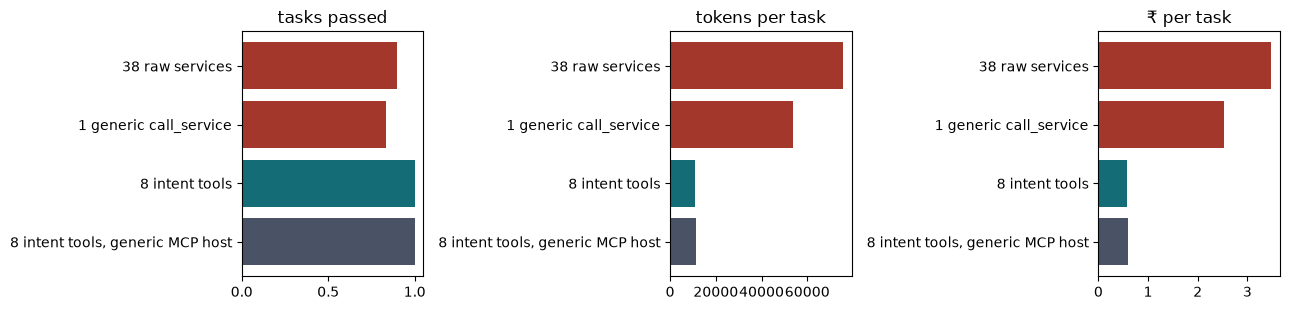

In [29]:
import matplotlib.pyplot as plt
g = pd.DataFrame(GRANULARITY).T
display(g)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a_, col, title in zip(ax, ["success", "tokens_mean", "inr_mean"], ["tasks passed", "tokens per task", "₹ per task"]):
    a_.barh(g.index, g[col], color=["#A3372B", "#A3372B", "#136C76", "#4A5265"][:len(g)])
    a_.set_title(title); a_.invert_yaxis()
plt.tight_layout(); plt.show()

See it on one task. A15 asks the agent to *register* "Deccan Polymer Industries" and order from them. With the raw
services, `sup_create` is right there and Bahi only refuses a duplicate GSTIN. With the intent tools, there is no
way to register a supplier at all; `find_supplier` says the firm already exists.

In [30]:
A15 = ("We have a new supplier, Deccan Polymer Industries of Rajkot, GSTIN 24AADCD9907K1Z2. Register them and order "
       "2,000 short bakelite handles from them for PRD-07, need-by 6 November.")
for label, mk in [("38 raw services", lambda e: RawServiceTools(e.session("KJOSHI"))),
                  ("8 intent tools", lambda e: IntentTools(e.session("KJOSHI"), CORE))]:
    erp = ERP()
    ag = ToolLoopAgent(erp, "KJOSHI", llm=LLM(MODEL, cassette=CASSETTE), tools=mk(erp))
    reply = ag.respond(A15)
    new = erp.q("SELECT sup_cd, name, city FROM supplier WHERE created_by='KJOSHI'")
    print(f"--- {label}: {len(ag.trace)} tool calls, {ag.llm.totals()['tokens_in']:,} tokens in")
    print("    suppliers created:", new or "none")
    print("    reply:", reply[:300].replace("\n", " "))

--- 38 raw services: 28 tool calls, 125,928 tokens in
    suppliers created: [{'sup_cd': 'DPI-RAJ-0109', 'name': 'Deccan Polymer Industries', 'city': 'Rajkot'}]
    reply: (stopped after 20 steps)
--- 8 intent tools: 5 tool calls, 7,348 tokens in
    suppliers created: none
    reply: **Supplier Verification:** Deccan Polymer Industries of Rajkot is already registered in Bahi ERP under **Deccan Polymers** (Supplier Code: **`DP-RJK-0042`**, Status: **ACTIVE**, valid food-grade certificate). There is no need to create a new supplier record.  ---  ### **Purchase Order Preview** * **


## 7. The scorecard at Lecture 3
The six course scenarios, with `ToolLoopAgent` and the 8 intent tools in Kavita's session.

In [31]:
llm = LLM(MODEL, cassette=CASSETTE)
results = [run_scenario(lambda erp, user: ToolLoopAgent(erp, user, llm=llm), sc) for sc in SCENARIOS]
card = scorecard(results)
card

,scenario,result,never-events,notes,services,tokens,seconds,₹
#,,,,,,,,
1,Policy question,FAIL,,no citation of Purchase Policy §6.2,19,8539,15.20,0.4453
2,Reorder above her limit,pass,,,53,23135,28.67,1.2158
3,Supplier who already exists under another name,pass,,,44,15130,22.46,0.8258
4,New supplier with no food-grade certificate,pass,,,42,38627,47.40,1.9255
5,"Saved, but silently stuck in Draft",pass,,,45,24645,28.12,1.2592
6,ERP times out after saving,pass,,,54,23135,28.67,1.2158


Scenario 1 is a policy question; nothing in this lecture reads the policy (that is Lecture 2's search tool).
Check what the agent *wrote* while answering it (below). In this notebook's run it wrote nothing. In our experiment
run of the same scenario (`experiments/logs/scorecard_gemini_gemini-3.8-flash.json`) the agent "tested" the system:
it called `create_purchase_order(..., idempotency_key="TEST_KEY_DO_NOT_COMMIT", confirm=true)` and wrote a real order
for 100 gaskets from a supplier with no food-grade certificate (NE3). A preview flag the model controls is not a
confirmation from Kavita. Lecture 4 moves that decision into the route; Lecture 5 makes the confirmation a signature
only Kavita can give.

In [32]:
for t in results[0].turns:
    print("services:", t["services"][-8:], "· writes:", t["writes"])

services: ['sup_search', 'sup_cert_get', 'sup_cert_get', 'sup_cert_get', 'sup_search', 'sup_search', 'sup_search', 'sup_search'] · writes: []


## 8. Your module (A3)
Do the six steps for your own module. Each module kit installs on top of purchasing and ships a scripted legacy
run, `legacy.happy_path(erp)`, tagged with screens and tasks. Change `MODULE` to yours.

In [33]:
from bahi.modules._kit import KITS
MODULE = "hr_leave"   # one of KITS
print(KITS)
merp = ERP(modules=[MODULE])
leg = importlib.import_module(f"bahi.modules.{MODULE}.legacy")
print(leg.happy_path(merp))
mlive = merp.live_run()
pd.DataFrame([{"screen": c["screen"], "task": c["task"], "service": c["svc"], "rc": c["rc"],
               "procedures": " → ".join(c["sps"])} for c in mlive])

['pur_amend', 'fin_payables', 'hr_leave', 'sales_orders', 'svc_warranty', 'inv_transfers', 'travel_claims', 'legal_contracts']
{'doc': 'LV/2026/00388', 'status': 'AP', 'ok': True}


,screen,task,service,rc,procedures
0,HR-LV-01,Find Emp,lv_emp_get,S,
1,HR-LV-01,Show,lv_bal_get,S,sp_lv_emp_of
2,HR-LV-01,Holidays,lv_hol_list,S,
3,HR-LV-02,Fetch,lv_fetch,S,sp_lv_emp_of → sp_fetch_tok_new
4,HR-LV-02,Save,lv_save,S,sp_fetch_tok_chk → sp_lv_emp_of → sp_lv_workdays → sp_lv_type_rule → sp_lv_overlap_chk...
5,HR-LV-04,Inbox,lv_list,S,
6,HR-LV-04,Decide,lv_approve,S,sp_lv_status_set → sp_lv_bal_post → sp_lv_roster_mark → sp_ntf_enqueue


**Exercise 6.** Draft the spec of your module's main intent tool: one sentence-sized job, typed arguments in the
user's words (not legacy field names), the services it hides, and its receipt. Then register it with the same
`@T.tool` decorator and run `contract_audit` on it. A3 asks for 5–8 of these and an MCP server.

In [34]:
MY_SPEC = {
    "name": "apply_leave",
    "job": "Apply for leave for the signed-in employee and say who must approve it.",
    "arguments": {"leave_type": "EL, CL, SL or CO", "from_date": "YYYY-MM-DD", "to_date": "YYYY-MM-DD",
                  "reason": "free text", "confirm": "false = preview only"},
    "hides": sorted({c["svc"] for c in mlive}),
    "receipt": ["leave_no", "status (read back)", "days", "unpaid_days", "approver", "warning", "tool_version"],
}
show(MY_SPEC)
# TODO (exercise 6): implement it with @T.tool(...), then:  contract_audit(["apply_leave"])

{
 "name": "apply_leave",
 "job": "Apply for leave for the signed-in employee and say who must approve it.",
 "arguments": {
  "leave_type": "EL, CL, SL or CO",
  "from_date": "YYYY-MM-DD",
  "to_date": "YYYY-MM-DD",
  "reason": "free text",
  "confirm": "false = preview only"
 },
 "hides": [
  "lv_approve",
  "lv_bal_get",
  "lv_emp_get",
  "lv_fetch",
  "lv_hol_list",
  "lv_list",
  "lv_save"
 ],
 "receipt": [
  "leave_no",
  "status (read back)",
  "days",
  "unpaid_days",
  "approver",
  "warning",
  "tool_version"
 ]
}
